# 03 - Maintenance optimization and scenarios

This notebook reviews the CP-SAT aircraft-to-hangar plan on the synthetic fleet
instance. It also re-validates the saved plan against the hard constraints, so the
schedule is auditable rather than just a chart.


In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
print("Repository root:", ROOT)


Repository root: D:\project learning


In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt

from flightops.config import load_config
from flightops.optimization.maintenance_planner import MaintenancePlan, evaluate_plan, validate_plan
from flightops.optimization.synthetic_fleet import build_instance

cfg = load_config()
results = json.loads((cfg.path("paths.optimization") / "scenario_results.json").read_text())
aircraft = pd.read_csv(cfg.path("paths.optimization") / "instance_aircraft.csv")
plan_df = pd.read_csv(cfg.path("paths.optimization") / "maintenance_plan_optimized.csv")
slots = pd.read_csv(cfg.path("paths.optimization") / "instance_slots.csv")
print(f"Aircraft: {len(aircraft)}, slots: {len(slots)}, horizon: {results['assumptions']['horizon_days']} days")


Aircraft: 15, slots: 52, horizon: 14 days


## 1. Baseline vs optimized cost

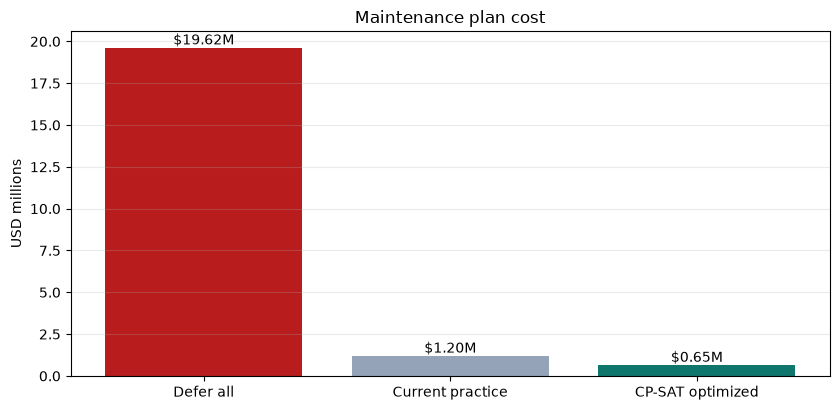

Saving vs current practice: $552,500 (46.1%)
Solver: OPTIMAL in 0.03s; unassigned 1 -> 0


In [3]:
base = results["baseline_vs_optimized"]
labels = ["Defer all", "Current practice", "CP-SAT optimized"]
values = [base["defer_all_cost_usd"], base["greedy_cost_usd"], base["optimized_cost_usd"]]
fig, ax = plt.subplots(figsize=(8.5, 4.2))
bars = ax.bar(labels, [v / 1e6 for v in values], color=["#b91c1c", "#94a3b8", "#0f766e"])
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"${value/1e6:.2f}M", ha="center", va="bottom")
ax.set(title="Maintenance plan cost", ylabel="USD millions")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()
print(f"Saving vs current practice: ${base['savings_vs_greedy_usd']:,.0f} ({base['savings_vs_greedy_pct']:.1f}%)")
print(f"Solver: {base['solver_status']} in {base['solve_seconds']:.2f}s; unassigned {base['greedy_unassigned']} -> {base['optimized_unassigned']}")


## 2. Schedule (Gantt)

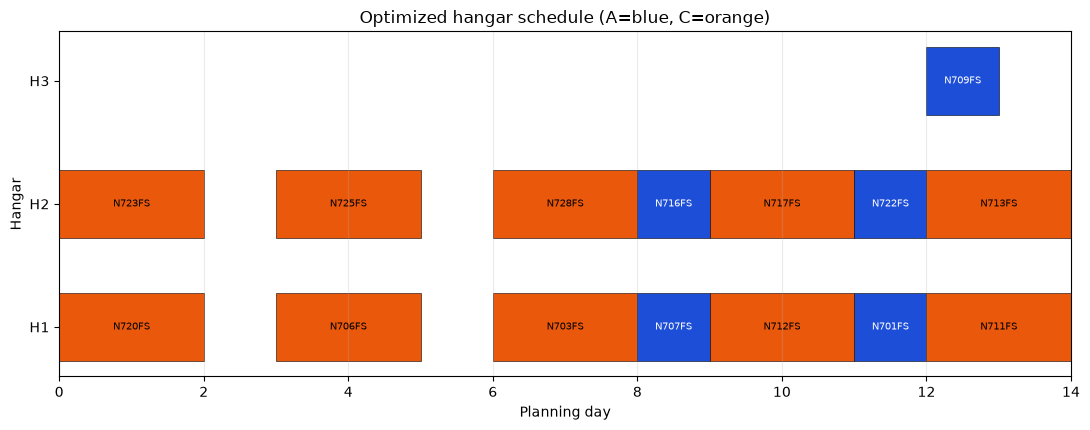

In [4]:
hangars = sorted(slots["hangar"].unique())
fig, ax = plt.subplots(figsize=(11, 4.4))
colors = {"A": "#1d4ed8", "C": "#ea580c"}
for row in plan_df.itertuples():
    slot = slots[slots["slot_id"] == row.assigned_slot].iloc[0]
    y = hangars.index(slot["hangar"])
    ax.barh(y, slot["duration_days"], left=slot["start_day"], height=0.55, color=colors[slot["check_type"]], edgecolor="black", linewidth=0.4)
    ax.text(slot["start_day"] + slot["duration_days"]/2, y, row.tail, ha="center", va="center", fontsize=7, color="white" if slot["check_type"] == "A" else "black")
ax.set_yticks(range(len(hangars)))
ax.set_yticklabels(hangars)
ax.set(title="Optimized hangar schedule (A=blue, C=orange)", xlabel="Planning day", ylabel="Hangar")
ax.set_xlim(0, results["assumptions"]["horizon_days"])
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


## 3. Constraint audit

In [5]:
instance = build_instance(cfg, scenario="baseline")
assignments = dict(zip(plan_df["tail"], plan_df["assigned_slot"]))
saved = MaintenancePlan(assignments=assignments, unassigned=[])
errors = validate_plan(instance, saved)
recomputed = evaluate_plan(instance, assignments)
print("Constraint violations:", errors if errors else "none")
print(f"Recomputed cost: ${recomputed.total_cost_usd:,.0f}")
print(f"Saved cost:      ${plan_df['total_cost_usd'].sum():,.0f}")
print("Breakdown:", recomputed.breakdown)


Constraint violations: none
Recomputed cost: $645,000
Saved cost:      $645,000
Breakdown: {'disruption_usd': 430000.0, 'early_maintenance_usd': 35000.0, 'aog_risk_usd': 180000.0, 'unassigned_penalty_usd': 0.0}


## 4. Disruption scenarios and sensitivity

In [6]:
scenarios = pd.DataFrame(results["scenarios"])
scenarios["uplift_vs_baseline_usd"] = scenarios["total_cost_usd"] - base["optimized_cost_usd"]
scenarios[["scenario", "assigned", "unassigned", "total_cost_usd", "uplift_vs_baseline_usd", "greedy_cost_usd", "savings_vs_greedy_usd"]]


,scenario,assigned,unassigned,total_cost_usd,uplift_vs_baseline_usd,greedy_cost_usd,savings_vs_greedy_usd
0,Defer all (no maintenance),0,15,19620000.0,18975000.0,NaN,NaN
1,Current practice: earliest feasible slot,14,1,1197500.0,552500.0,NaN,NaN
2,CP-SAT optimized,15,0,645000.0,0.0,NaN,NaN
3,Disruption: hangar_closure,15,0,657500.0,12500.0,1187500.0,530000.0
4,Disruption: rul_stress,14,3,3641500.0,2996500.0,3744000.0,102500.0
5,Disruption: demand_surge,15,0,785500.0,140500.0,940500.0,155000.0


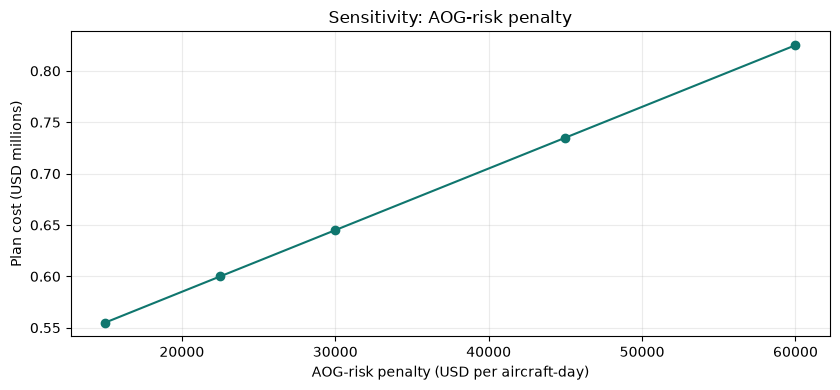

,aog_risk_penalty_usd_per_day,total_cost_usd,assigned,unassigned,aog_risk_usd,early_maintenance_usd
0,15000.0,555000.0,15,0,90000.0,35000.0
1,22500.0,600000.0,15,0,135000.0,35000.0
2,30000.0,645000.0,15,0,180000.0,35000.0
3,45000.0,735000.0,15,0,270000.0,35000.0
4,60000.0,825000.0,15,0,360000.0,35000.0


In [7]:
sens = pd.DataFrame(results["sensitivity"])
fig, ax = plt.subplots(figsize=(8.5, 4.0))
ax.plot(sens["aog_risk_penalty_usd_per_day"], sens["total_cost_usd"] / 1e6, marker="o", color="#0f766e")
ax.set(title="Sensitivity: AOG-risk penalty", xlabel="AOG-risk penalty (USD per aircraft-day)", ylabel="Plan cost (USD millions)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
sens


## 5. Limitations

- The fleet, slots and costs are synthetic and deterministic from the project seed.
- The model assumes one aircraft position per hangar-day and pre-computed costs.
- A real deployment needs live CAMO data, crew constraints, parts availability and
  an approved maintenance programme. The solver is a planning aid, not a
  release-to-service authority.
